### 1. Import das bibliotecas e definição da função de leitura

In [1]:
import requests
import pandas as pd

def read_ckan_sql(resource_id):
    url = "https://dados.uffs.edu.br/api/3/action/datastore_search_sql"

    limit = 1000
    offset = 0
    all_records = []

    while True:
        sql = f'''
        SELECT *
        FROM "{resource_id}"
        LIMIT {limit}
        OFFSET {offset}
        '''

        response = requests.get(url, params={"sql": sql})
        data = response.json()

        records = data["result"]["records"]

        if not records:
            break

        all_records.extend(records)
        offset += limit

        print(f"Baixados: {offset}")

    df = pd.DataFrame(all_records)
    return df

### 2. Passa o id dos dados pra função de leitura, e transforma o resultado em um dataframe pandas

In [11]:
df_turmas = read_ckan_sql("670bc744-2570-4e2a-b73b-3acf2039a7c1")
print("Número de registros:", len(df_turmas))

Baixados: 1000
Baixados: 2000
Baixados: 3000
Baixados: 4000
Baixados: 5000
Baixados: 6000
Baixados: 7000
Baixados: 8000
Baixados: 9000
Baixados: 10000
Baixados: 11000
Baixados: 12000
Baixados: 13000
Baixados: 14000
Baixados: 15000
Baixados: 16000
Baixados: 17000
Baixados: 18000
Baixados: 19000
Baixados: 20000
Baixados: 21000
Baixados: 22000
Baixados: 23000
Baixados: 24000
Baixados: 25000
Baixados: 26000
Baixados: 27000
Baixados: 28000
Baixados: 29000
Baixados: 30000
Baixados: 31000
Baixados: 32000
Baixados: 33000
Baixados: 34000
Baixados: 35000
Baixados: 36000
Baixados: 37000
Baixados: 38000
Baixados: 39000
Baixados: 40000
Baixados: 41000
Baixados: 42000
Baixados: 43000
Baixados: 44000
Baixados: 45000
Baixados: 46000
Baixados: 47000
Número de registros: 46540


### 3. Mostra os 5 primeiros registros

In [12]:
df_turmas.head()

,_id,_full_text,nome_campus,ano,semestre,cod_ccr,nome_ccr,ch_ccr,id_unico_turma,id_relativo_turma,...,cursos_turma,quantidade_docentes,lista_docentes,lista_ch_docentes,vagas_turma,qtd_inscritos,qtd_passaram_pela_turma,qtd_aprovados,sit_turma,data_atualizacao
0,1,"'-04':32 '-13':33 '1':4,12,19 '15.66807':36 '1...",Cerro Largo,2010,1,GCS001,INTRODUÇÃO À ADMINISTRAÇÃO,60,16,16,...,DESENVOLVIMENTO RURAL E GESTÃO AGROINDUSTRIAL,1,LOUISE DE LIRA ROEDEL BOTELHO,60,50,69,69,59,CONSOLIDADA,2026-04-13T02:30:15.668070
1,2,"'-04':26 '-13':27 '1':4,12,15 '15.66807':30 '2...",Cerro Largo,2010,1,GEX002,INTRODUÇÃO À INFORMÁTICA,60,38,38,...,AGRONOMIA,1,RENEO PEDRO PREDIGER,60,50,48,48,43,CONSOLIDADA,2026-04-13T02:30:15.668070
2,3,"'-04':30 '-13':31 '1':4,12,19 '15.66807':34 '2...",Cerro Largo,2010,1,GEX002,INTRODUÇÃO À INFORMÁTICA,60,39,39,...,DESENVOLVIMENTO RURAL E GESTÃO AGROINDUSTRIAL,1,RENEO PEDRO PREDIGER,60,50,67,67,58,CONSOLIDADA,2026-04-13T02:30:15.668070
3,4,"'-04':30 '-13':31 '1':4,12,18 '15.66807':34 '2...",Cerro Largo,2010,1,GEX002,INTRODUÇÃO À INFORMÁTICA,60,40,40,...,ENGENHARIA AMBIENTAL E SANITÁRIA,1,IARA DENISE ENDRUWEIT BATTISTI,60,50,40,40,27,CONSOLIDADA,2026-04-13T02:30:15.668070
4,5,"'-04':27 '-13':28 '1':4,14,17 '15.66807':31 '2...",Cerro Largo,2010,1,GLA008,LEITURA E EXPRESSÃO ESCRITA I,60,75,75,...,AGRONOMIA,1,CRISTIANE HORST,60,50,49,49,47,CONSOLIDADA,2026-04-13T02:30:15.668070


### 4. Leitura do dicionário de dados do arquivo

In [13]:
df_dicionario_dados = read_ckan_sql("d05954c6-9af5-4641-bdc8-88d95949c760")
print("Número de registros:", len(df_dicionario_dados))

Baixados: 1000
Número de registros: 20


### 5. Mostra os registros

In [6]:
df_dicionario_dados

,_id,_full_text,coluna,tipo,rotulo,descricao
0,1,"'campus':2,6,9 'nom':1,4,7 'ofert':11 'text':3...",nome_campus,text,Nome do campus,Nome do campus de oferta da turma.
1,2,"'ano':1,3,6 'integ':2 'ofert':5,8 'turm':10",ano,integer,Ano de oferta,Ano de oferta da turma.
2,3,"'integ':2 'ofert':5,8 'semestr':1,3,6 'turm':10",semestre,integer,Semestre de oferta,Semestre de oferta da turma.
3,4,"'ccr':2,6 'cod':1 'component':9 'curricul':10 ...",cod_ccr,text,Código do CCR,Código do componente curricular na UFFS.
4,5,"'ccr':2,6 'component':9 'curricul':10 'nom':1,...",nome_ccr,text,Nome do CCR,Nome do componente curricular na UFFS.
5,6,"'carg':4,8 'ccr':2,7 'ch':1 'component':11 'cu...",ch_ccr,numeric,Carga horária do CCR,Carga horária do componente curricular na UFFS.
6,7,"'antig':23 'id':1,5,20 'identific':9,12 'integ...",id_unico_turma,integer,ID único da turma,Identificador que permite identificar unicamen...
7,8,"'acompanh':40 'ano':16,42 'antig':50 'ccr':21,...",id_relativo_turma,integer,ID relativo da turma,Identificador que permite diferenciar turmas d...
8,9,"'curs':2,6,9 'integ':3 'númer':7 'ofert':16 'q...",quantidade_cursos,integer,Quantidade de Cursos,Número de cursos para os quais a turma foi ofe...
9,10,"'cas':17 'cod':1 'curs':3,8,11 'códig':6,9 'ex...",cod_uffs_cursos_turma,text,Código dos cursos,Código dos cursos de oferta da turma. Em caso ...


### Funções úteis

In [14]:
# 1. Função para formatar o número no padrão moeda do Brasil
from pandas.io.formats.style import Styler
def formatar_moeda_br(valor):
    if pd.isna(valor):
        return "R$ 0,00"
    
    # Formata com 2 casas decimais no padrão americano (ex: 1,234,567.89)
    valor_str = f"{valor:,.2f}"
    
    # Troca a vírgula por um 'X' temporário, o ponto por vírgula, e o 'X' por ponto
    valor_br = valor_str.replace(",", "X").replace(".", ",").replace("X", ".")
    
    return f"R$ {valor_br}"

## Análises iniciais

curso_individual
PEDAGOGIA                           1634
ADMINISTRAÇÃO                       1502
LETRAS - PORTUGUÊS E ESPANHOL       1476
AGRONOMIA                           1445
CIÊNCIA DA COMPUTAÇÃO               1409
ENGENHARIA AMBIENTAL E SANITÁRIA    1234
CIÊNCIAS SOCIAIS                     896
HISTÓRIA                             862
GEOGRAFIA                            846
FILOSOFIA                            833
ENFERMAGEM                           719
MEDICINA                             650
MATEMÁTICA                           472
EDUCAÇÃO ESPECIAL INCLUSIVA           14
CIÊNCIAS ECONÔMICAS                   11
Name: count, dtype: int64


C:\Users\marco\AppData\Local\Temp\ipykernel_21628\3197822878.py:45: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  barras = sns.barplot(x=gargalos['taxa_aprovacao_geral'], y=labels, palette='magma')


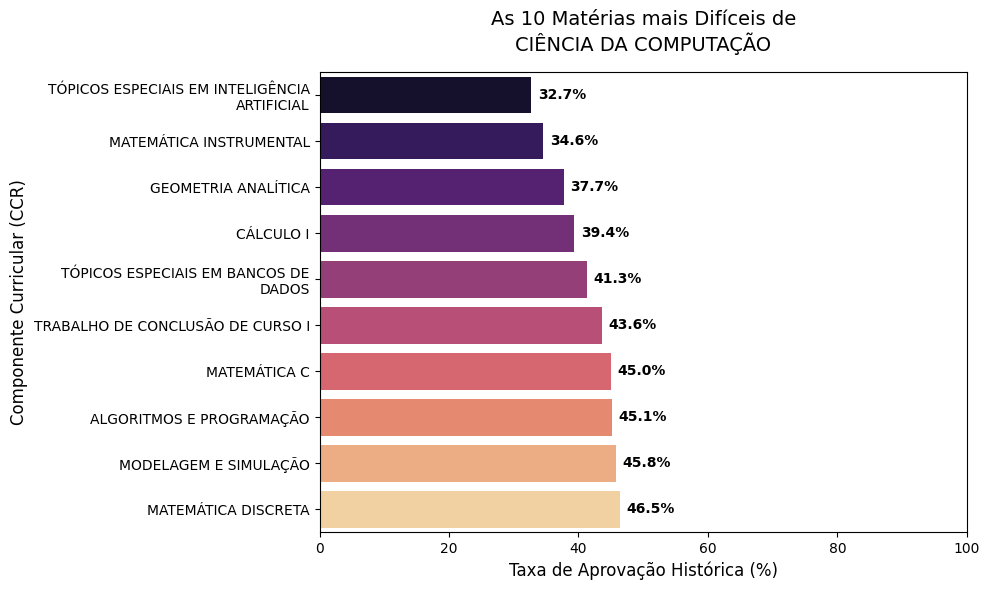

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import textwrap

# 1. Filtro inicial para Chapecó e removendo turmas vazias
df_turmas_chapeco = df_turmas[df_turmas['nome_campus'] == 'Chapecó'].copy()
df_turmas_chapeco = df_turmas_chapeco[df_turmas_chapeco['sit_turma'] == 'CONSOLIDADA']

# Como turmas podem ser de mais de um curso, nós separamos pelo ponto e vírgula e "explodimos"
df_turmas_chapeco['curso_individual'] = df_turmas_chapeco['cursos_turma'].dropna().str.split(';')
df_explodido = df_turmas_chapeco.explode('curso_individual')

# Removendo espaços em branco que sobram no começo ou fim dos nomes
df_explodido['curso_individual'] = df_explodido['curso_individual'].str.strip()

# ---------------------------------------------------------
# FUNÇÃO PARA GERAR O GRÁFICO POR CURSO
# ---------------------------------------------------------
def plotar_gargalo_por_curso(df, nome_do_curso, min_alunos=50):
    # 1. Filtra apenas as turmas que atendem a este curso
    df_curso = df[df['curso_individual'] == nome_do_curso]
    
    if df_curso.empty:
        print(f"Ops! Não encontrei nenhum dado para o curso: {nome_do_curso}")
        return
    
    # 2. Agrupa as matérias (CCRs) somando os alunos da história toda
    agrupado_ccr = df_curso.groupby('nome_ccr').agg(
        total_alunos=('qtd_passaram_pela_turma', 'sum'),
        total_aprovados=('qtd_aprovados', 'sum')
    ).reset_index()

    # 3. Calcula a taxa
    agrupado_ccr['taxa_aprovacao_geral'] = (agrupado_ccr['total_aprovados'] / agrupado_ccr['total_alunos']) * 100

    # 4. Filtra matérias com um mínimo de alunos para não pegar optativas muito vazias
    gargalos = agrupado_ccr[agrupado_ccr['total_alunos'] >= min_alunos].sort_values('taxa_aprovacao_geral', ascending=True).head(10)

    # 5. Prepara o visual (Quebra de texto)
    labels = [textwrap.fill(str(texto), width=35) for texto in gargalos['nome_ccr']]

    # 6. Plota o Gráfico
    plt.figure(figsize=(10, 6))
    barras = sns.barplot(x=gargalos['taxa_aprovacao_geral'], y=labels, palette='magma')
    
    plt.title(f'As 10 Matérias mais Difíceis de\n{nome_do_curso}', fontsize=14, pad=15)
    plt.xlabel('Taxa de Aprovação Histórica (%)', fontsize=12)
    plt.ylabel('Componente Curricular (CCR)', fontsize=12)

    # Adiciona a % nas barras
    for i, valor in enumerate(gargalos['taxa_aprovacao_geral']):
        plt.text(valor + 1, i, f'{valor:.1f}%', va='center', fontsize=10, color='black', fontweight='bold')

    plt.xlim(0, 100)
    plt.tight_layout()
    plt.show()


print(df_explodido['curso_individual'].value_counts().head(20))

# Agora chame a função com o nome exato do curso que você quer investigar. 
# Exemplo (substitua pelo nome exato do seu curso, como aparece no print acima):
plotar_gargalo_por_curso(df_explodido, 'CIÊNCIA DA COMPUTAÇÃO')

# Você pode chamar essa mesma função várias vezes em células diferentes do Jupyter!
# plotar_gargalo_por_curso(df_explodido, 'Agronomia - Bacharelado - Integral')